# 03 Point-in-time features

For target day D and run cutoff (D-1 07:00 or 09:00 UK), use only the latest forecast vintage available at the cutoff. Development days only (`dev_only`).

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _common import load, load_all, to_uk, settlement_day, dev_only, UK_TZ

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

def show():
    for ax in plt.gcf().axes:
        ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

price = dev_only(load("imbalance_price")).set_index("period_start")["price_gbp_per_mwh"]
dev_days = pd.Index(sorted(set(settlement_day(price.index.to_series()))))
print(len(dev_days), "development days:", dev_days[0], "to", dev_days[-1])

674 development days: 2024-10-01 to 2026-08-05


## 1. Cutoff times

For day D, the run happens at `HH:00` UK on D-1. Build that as a UK-local timestamp and convert to UTC, so clock-change days are handled by the timezone database rather than by adding 24 hours.

In [2]:
def cutoff_utc(day, hour):
    """UTC instant of HH:00 UK local on the day before `day`."""
    d1 = pd.Timestamp(day) - pd.Timedelta(days=1)
    return (d1 + pd.Timedelta(hours=hour)).tz_localize(UK_TZ, ambiguous=False, nonexistent="shift_forward").tz_convert("UTC")

# check around the clock changes
for d in ["2025-03-30", "2025-03-31", "2025-10-26", "2025-10-27", "2026-03-29"]:
    print(d, "07:00 cutoff in UTC:", cutoff_utc(d, 7), "| 09:00:", cutoff_utc(d, 9))

2025-03-30 07:00 cutoff in UTC: 2025-03-29 07:00:00+00:00 | 09:00: 2025-03-29 09:00:00+00:00
2025-03-31 07:00 cutoff in UTC: 2025-03-30 06:00:00+00:00 | 09:00: 2025-03-30 08:00:00+00:00
2025-10-26 07:00 cutoff in UTC: 2025-10-25 06:00:00+00:00 | 09:00: 2025-10-25 08:00:00+00:00
2025-10-27 07:00 cutoff in UTC: 2025-10-26 07:00:00+00:00 | 09:00: 2025-10-26 09:00:00+00:00
2026-03-29 07:00 cutoff in UTC: 2026-03-28 07:00:00+00:00 | 09:00: 2026-03-28 09:00:00+00:00


## 2. Latest-vintage-at-cutoff selection

Each forecast row has `period_start` (target) and an availability time: `received_at`, falling back to `issued_at` where `received_at` is missing. For each target period, the run cutoff is that period's UK day D, shifted to D-1 at the run hour. Keep rows whose availability is at or before the cutoff, then keep the row with the latest availability per target period.

Two details matter. `received_at` includes later backfills, so a row can carry an old `issued_at` but only land in the database after the cutoff; using `received_at` where present excludes it. And the selection is per target period, so different periods of the same day can come from different vintages (the demand forecast is the clearest case).

In [3]:
def pit_snapshot(df, hour, value_cols, key="period_start"):
    """Latest vintage per target period available at D-1 `hour`:00 UK. Returns one row per period."""
    df = df.copy()
    df["avail"] = df["received_at"].fillna(df["issued_at"])
    day = settlement_day(df[key])
    cut = {d: cutoff_utc(d, hour) for d in sorted(set(day))}   # one cutoff per UK day
    df["cutoff"] = day.map(cut)
    ok = df[df["avail"] <= df["cutoff"]]
    ok = ok.sort_values([key, "avail"]).drop_duplicates(key, keep="last")
    ok["vintage_age_h"] = (ok["cutoff"] - ok["avail"]).dt.total_seconds() / 3600
    assert (ok["avail"] <= ok["cutoff"]).all()  # no look-ahead
    return ok.set_index(key)[value_cols + ["vintage_age_h"]]

raw = {n: dev_only(load(n)) for n in ["demand_forecast_elexon", "wind_forecast_elexon", "wind_solar_forecast_embedded"]}
print({k: len(v) for k, v in raw.items()})

{'demand_forecast_elexon': 1896361, 'wind_forecast_elexon': 389590, 'wind_solar_forecast_embedded': 2311966}


In [4]:
snap = {}
for hour in (7, 9):
    snap[hour] = {
        "demand": pit_snapshot(raw["demand_forecast_elexon"], hour, ["demand_mw"]),
        "wind": pit_snapshot(raw["wind_forecast_elexon"], hour, ["wind_mw"]),
        "emb": pit_snapshot(raw["wind_solar_forecast_embedded"], hour, ["embedded_wind_mw", "embedded_solar_mw"]),
    }
for hour in (7, 9):
    for name, s in snap[hour].items():
        a = s.vintage_age_h
        print(f"{hour:02d}:00  {name:7s} periods {len(s):6d}   vintage age (h) median {a.median():5.1f}  min {a.min():5.1f}  max {a.max():5.1f}")

07:00  demand  periods   6730   vintage age (h) median   0.2  min   0.0  max   0.7
07:00  wind    periods  16150   vintage age (h) median   0.5  min   0.5  max   8.5
07:00  emb     periods  32333   vintage age (h) median   0.8  min   0.0  max  40.8
09:00  demand  periods  32238   vintage age (h) median   0.2  min   0.0  max   1.7
09:00  wind    periods  16174   vintage age (h) median   2.5  min   0.1  max  10.5
09:00  emb     periods  32333   vintage age (h) median   0.8  min   0.0  max  42.8


## 3. Put everything on the half-hour grid

The Elexon wind forecast is hourly (value stamped at the hour start). Each half-hour period takes the value of the hour it falls inside. The embedded forecast is half-hourly. Coverage is the share of price periods with a value.

In [5]:
grid = price.index

def assemble(hour):
    s = snap[hour]
    f = pd.DataFrame(index=grid)
    f["demand_mw"] = s["demand"]["demand_mw"].reindex(grid)
    f["wind_mw"] = s["wind"]["wind_mw"].reindex(grid.floor("h")).to_numpy()
    for c in ["embedded_wind_mw", "embedded_solar_mw"]:
        f[c] = s["emb"][c].reindex(grid)
    f["demand_age_h"] = s["demand"]["vintage_age_h"].reindex(grid)
    return f

feat = {h: assemble(h) for h in (7, 9)}
print(pd.DataFrame({f"{h:02d}:00": feat[h].notna().mean() for h in (7, 9)}).round(3).to_string())

                   07:00  09:00
demand_mw          0.207  0.994
wind_mw            0.995  0.997
embedded_wind_mw   0.996  0.996
embedded_solar_mw  0.996  0.996
demand_age_h       0.207  0.994


## 4. How much do the 07:00 and 09:00 forecasts differ?

If the two vintages are nearly identical, the 09:00 run adds little. Compare periods that have a value at both cutoffs.

In [6]:
d = pd.DataFrame({
    "demand 09 - 07": feat[9]["demand_mw"] - feat[7]["demand_mw"],
    "wind 09 - 07": feat[9]["wind_mw"] - feat[7]["wind_mw"],
    "emb wind 09 - 07": feat[9]["embedded_wind_mw"] - feat[7]["embedded_wind_mw"],
    "emb solar 09 - 07": feat[9]["embedded_solar_mw"] - feat[7]["embedded_solar_mw"],
})
print("share of comparable periods where the value is identical at both cutoffs:")
print((d == 0).where(d.notna()).mean().round(3).to_string())
print()
print(d.describe(percentiles=[.05, .5, .95]).round(0).to_string())

share of comparable periods where the value is identical at both cutoffs:
demand 09 - 07       0.962
wind 09 - 07         0.554
emb wind 09 - 07     0.063
emb solar 09 - 07    0.511

       demand 09 - 07  wind 09 - 07  emb wind 09 - 07  emb solar 09 - 07
count          6710.0       32203.0           32236.0            32236.0
mean              3.0          -4.0              -2.0                2.0
std              62.0         260.0              64.0              101.0
min           -1049.0       -2975.0            -523.0             -918.0
5%                0.0        -410.0            -102.0             -144.0
50%               0.0           0.0               0.0                0.0
95%               0.0         392.0              98.0              157.0
max            1057.0        2027.0             447.0             1079.0


## 5. Scale and overlap of the forecast features

Before combining demand, wind and embedded generation into a net-demand variable, check their scales and how they correlate. The demand forecast excludes embedded generation, which appears only as lower demand, so subtracting embedded output from it would double-count.

In [7]:
f = feat[9].dropna(subset=["demand_mw", "wind_mw", "embedded_wind_mw", "embedded_solar_mw"])
print(f[["demand_mw", "wind_mw", "embedded_wind_mw", "embedded_solar_mw"]].describe().round(0).to_string())
print()
print(f[["demand_mw", "wind_mw", "embedded_wind_mw", "embedded_solar_mw"]].corr().round(2).to_string())

       demand_mw  wind_mw  embedded_wind_mw  embedded_solar_mw
count    32026.0  32026.0           32026.0            32026.0
mean     26415.0   9406.0            2039.0             2048.0
std       6238.0   5148.0            1294.0             3177.0
min      12080.0    614.0             180.0                0.0
25%      21668.0   5050.0             980.0                0.0
50%      25204.0   8670.0            1725.0               36.0
75%      30390.0  13240.0            2827.0             3248.0
max      46820.0  21539.0            5897.0            14607.0

                   demand_mw  wind_mw  embedded_wind_mw  embedded_solar_mw
demand_mw               1.00     0.08              0.04              -0.27
wind_mw                 0.08     1.00              0.94              -0.20
embedded_wind_mw        0.04     0.94              1.00              -0.13
embedded_solar_mw      -0.27    -0.20             -0.13               1.00


## 6. Do the features relate to price?

Correlation of price with each 09:00 feature: raw, Spearman (price tail is fat), and after removing the hour-of-day mean from both sides so a shared intraday shape is not mistaken for a relationship.

In [8]:
X = feat[9].join(price.rename("price"))
loc = to_uk(X.index.to_series())
X["hour"] = loc.dt.hour + loc.dt.minute / 60
X = X.dropna(subset=["price", "demand_mw", "wind_mw", "embedded_wind_mw", "embedded_solar_mw"])
X["wind_total_mw"] = X["wind_mw"] + X["embedded_wind_mw"]
cols = ["demand_mw", "wind_mw", "embedded_wind_mw", "embedded_solar_mw", "wind_total_mw"]

dm = X[cols + ["price"]] - X.groupby("hour")[cols + ["price"]].transform("mean")
out = pd.DataFrame({
    "pearson": X[cols].corrwith(X["price"]),
    "spearman": X[cols].corrwith(X["price"], method="spearman"),
    "pearson, hour-demeaned": dm[cols].corrwith(dm["price"]),
})
print(len(X), "periods")
print(out.round(3).to_string())

32026 periods
                   pearson  spearman  pearson, hour-demeaned
demand_mw            0.295     0.346                   0.251
wind_mw             -0.220    -0.243                  -0.228
embedded_wind_mw    -0.240    -0.265                  -0.247
embedded_solar_mw   -0.119    -0.052                  -0.124
wind_total_mw       -0.226    -0.249                  -0.234


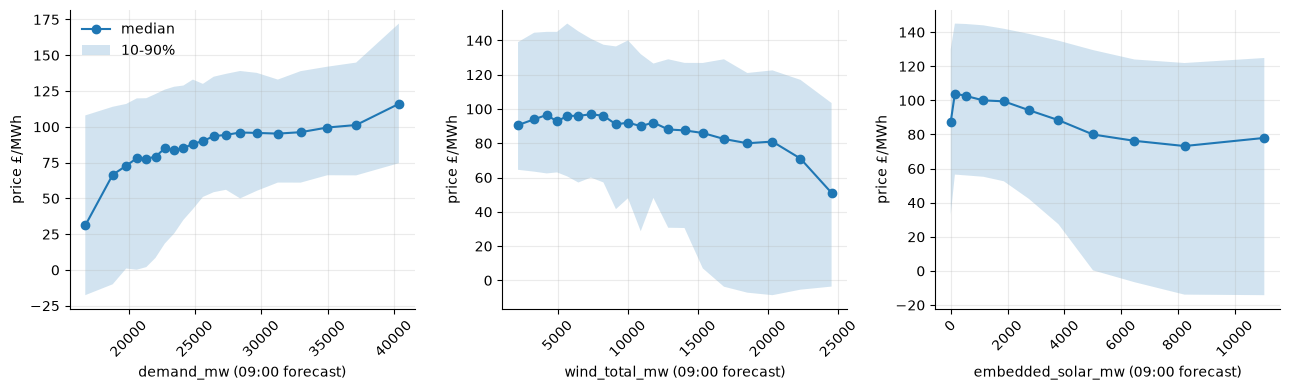

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, c in zip(axes, ["demand_mw", "wind_total_mw", "embedded_solar_mw"]):
    q = pd.qcut(X[c], 20, duplicates="drop")
    g = X.groupby(q, observed=True)["price"].agg(["median", lambda s: s.quantile(.1), lambda s: s.quantile(.9)])
    x = X.groupby(q, observed=True)[c].mean()
    ax.plot(x, g["median"], marker="o", label="median")
    ax.fill_between(x, g.iloc[:, 1], g.iloc[:, 2], alpha=0.2, label="10-90%")
    ax.set_xlabel(c + " (09:00 forecast)"); ax.set_ylabel("price \u00a3/MWh")
axes[0].legend(frameon=False)
show()

## 7. Daily margin forecast

`margin_daily` records only the publication date, not the time. A publication dated D-1 might or might not be out at 09:00, so use only publications dated D-2 or earlier (safe at both cutoffs), and check how often one exists.

In [10]:
mdy = dev_only(load("margin_daily"), col="issued_at").copy()
mdy["day"] = pd.to_datetime(mdy["day"])
mdy["issued_day"] = to_uk(mdy["issued_at"]).dt.tz_localize(None).dt.normalize()
mdy["lead_days"] = (mdy["day"] - mdy["issued_day"]).dt.days
print(mdy["lead_days"].value_counts().sort_index().to_string())
safe = mdy[mdy["lead_days"] >= 2]
latest = safe.sort_values("issued_day").drop_duplicates("day", keep="last").set_index("day")
print("development days with a safe publication:", latest.index.isin(pd.to_datetime(dev_days)).sum(), "of", len(dev_days))

lead_days
2    677
3    671
development days with a safe publication: 674 of 674


In [11]:
dp = price.groupby(settlement_day(price.index.to_series())).mean()
dp.index = pd.to_datetime(dp.index)
M = latest.join(dp.rename("mean_price"), how="inner")
cols_m = ["peak_demand_forecast_mw", "minimum_demand_forecast_mw", "generation_availability_margin_mw",
          "national_surplus_mw", "constrained_plant_mw", "negative_reserve_mw"]
print(len(M), "days")
print(M[cols_m].corrwith(M["mean_price"]).round(3).rename("corr with daily mean price").to_string())

674 days
peak_demand_forecast_mw              0.260
minimum_demand_forecast_mw           0.381
generation_availability_margin_mw   -0.416
national_surplus_mw                 -0.411
constrained_plant_mw                -0.278
negative_reserve_mw                 -0.388


## Findings (development days only)

- **Selection works and is leak-free.** Latest vintage with availability (`received_at`, else `issued_at`) at or before D-1 07:00/09:00 UK, per target period; asserted in code. Cutoffs are built in UK local time, so clock-change days shift correctly.
- **Coverage.** Wind (Elexon) and embedded wind/solar cover ~99.5% of periods at both cutoffs. The demand forecast covers only 20.7% of periods at 07:00 (the full-day vintage lands ~08:48) but 99.4% at 09:00. So at 07:00 demand is mostly missing and the model must either handle missing demand or omit it; at 09:00 it is available.
- **07:00 vs 09:00.** Demand is identical across the two cutoffs for 96% of the periods that exist at both. Wind (Elexon) is identical for 55%, embedded solar 51%, embedded wind only 6%; typical differences are a few hundred MW (Elexon wind 5-95%: -410 to +392 MW). The 09:00 run therefore mainly adds the demand forecast and small updates to the wind and solar forecasts.
- **Scale and overlap.** Mean demand 26.4 GW, Elexon wind 9.4 GW, embedded wind 2.0 GW, embedded solar 2.0 GW. Elexon wind and embedded wind correlate at 0.94 (same weather), so they carry largely the same information; demand and embedded solar correlate at -0.27 (solar lowers metered demand). Net demand should not subtract embedded output from the demand forecast, which already reflects it.
- **Relationship to price (09:00 features, 32,026 periods).** Price rises with forecast demand (Pearson 0.30, Spearman 0.35, 0.25 after removing the hour-of-day mean) and falls with wind (-0.22 to -0.25; total wind -0.23 hour-demeaned). Embedded solar is weaker (-0.12 raw, -0.05 Spearman). The binned plots show the effect is non-linear: price drops steeply at the lowest demand (median ~£31 in the lowest demand bin), and at the highest wind the median falls to about £51 and the 10th percentile goes negative; across the middle of the range the relationship is flat. Correlations are modest, so these features explain part of the price but not most of it.
- **Daily margin.** Publications are always 2 or 3 days ahead, so one dated D-2 or earlier exists for every development day and is safe at both cutoffs. Correlations with daily mean price are -0.42 (generation availability margin), -0.41 (national surplus), -0.39 (negative reserve) and 0.38 (minimum demand). These are daily features correlated with a drifting price level, so part of that correlation may be the level shift rather than a causal link; check within a fold before relying on it.
- **Implication for 04/modelling.** Features: hour/day/season, 09:00 demand, wind (use total or Elexon only, given the overlap), embedded solar, daily margin, a recent price level, with demand treated as unavailable at 07:00 except for the first few hours. Non-linearity suggests trees or splines rather than a linear model alone.